# ML Practical 7
### Name: Aryan Karande
### Section: A-A3
### Roll No: 38

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
df = pd.read_csv('/content/bank_notes.csv')
display(df.head())

,variance,skewness,curtosis,entropy,Target
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [3]:
print("Dataset Shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())
display(df.describe())

Dataset Shape: (1372, 5)

Missing values per column:
variance    0
skewness    0
curtosis    0
entropy     0
Target      0
dtype: int64


,variance,skewness,curtosis,entropy,Target
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


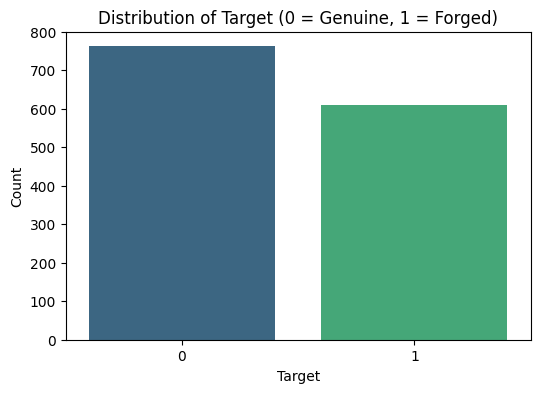

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Target', palette='viridis', hue='Target', legend=False)
plt.title('Distribution of Target (0 = Genuine, 1 = Forged)')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

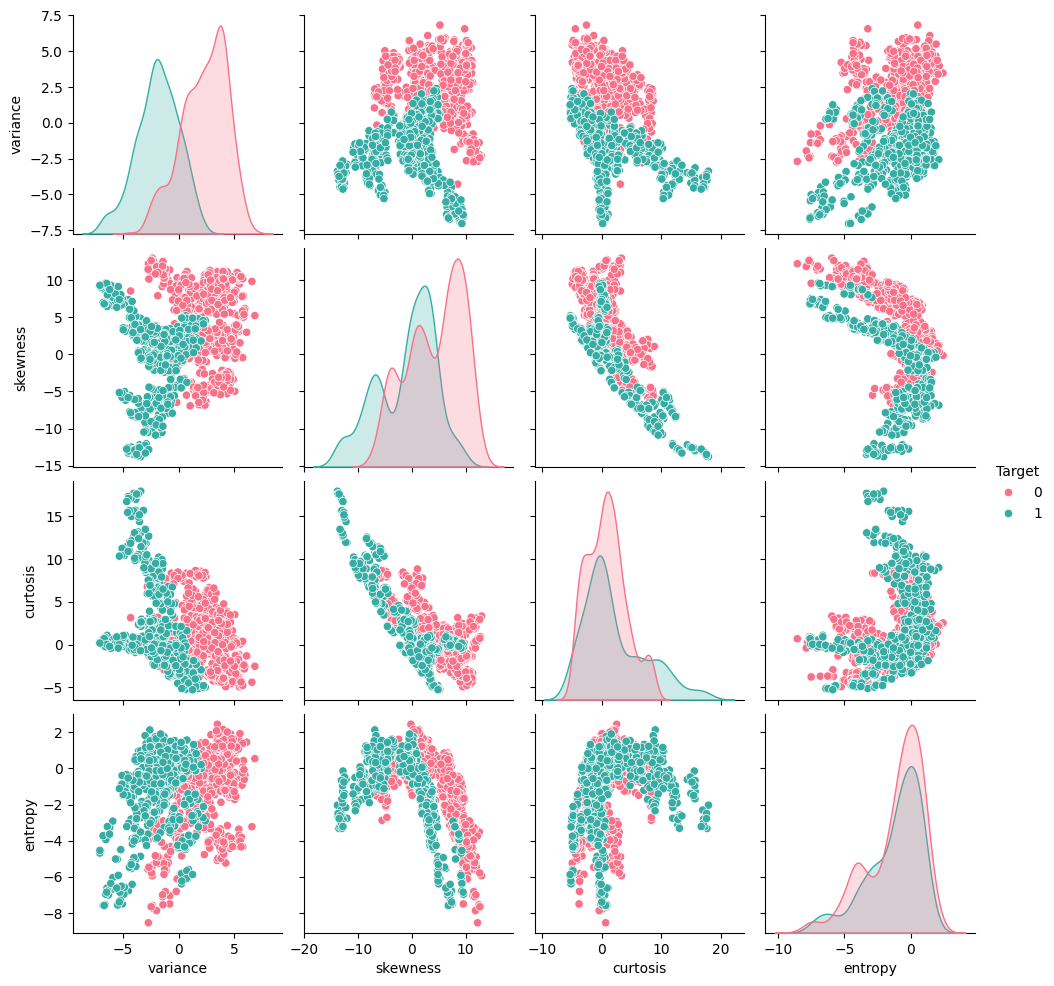

In [5]:
sns.pairplot(df, hue='Target', palette='husl', diag_kind='kde')
plt.show()

In [9]:
df.tail()

,variance,skewness,curtosis,entropy,Target
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1
1371,-2.54190,-0.65804,2.6842,1.19520,1


In [10]:
df.duplicated().sum()

np.int64(24)

/tmp/ipykernel_2147/4294100182.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Genuine (0)', 'Forged (1)'])


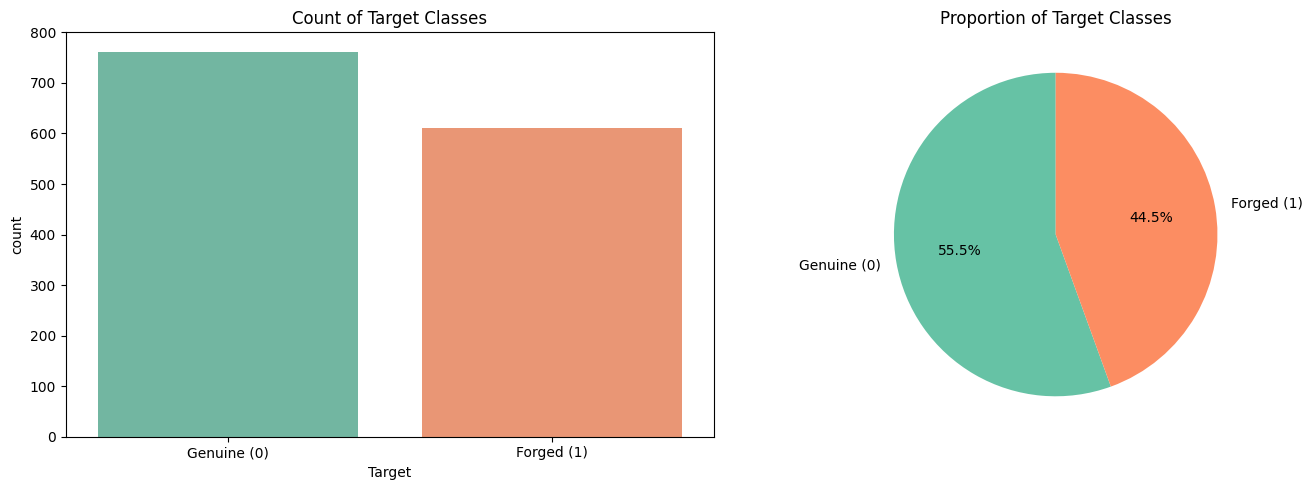

In [11]:
# 1. Countplot & Pie Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Countplot
sns.countplot(data=df, x='Target', palette='Set2', ax=axes[0], hue='Target', legend=False)
axes[0].set_title('Count of Target Classes')
axes[0].set_xticklabels(['Genuine (0)', 'Forged (1)'])

# Pie Chart
target_counts = df['Target'].value_counts()
axes[1].pie(target_counts, labels=['Genuine (0)', 'Forged (1)'], autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Set2'))
axes[1].set_title('Proportion of Target Classes')

plt.tight_layout()
plt.show()

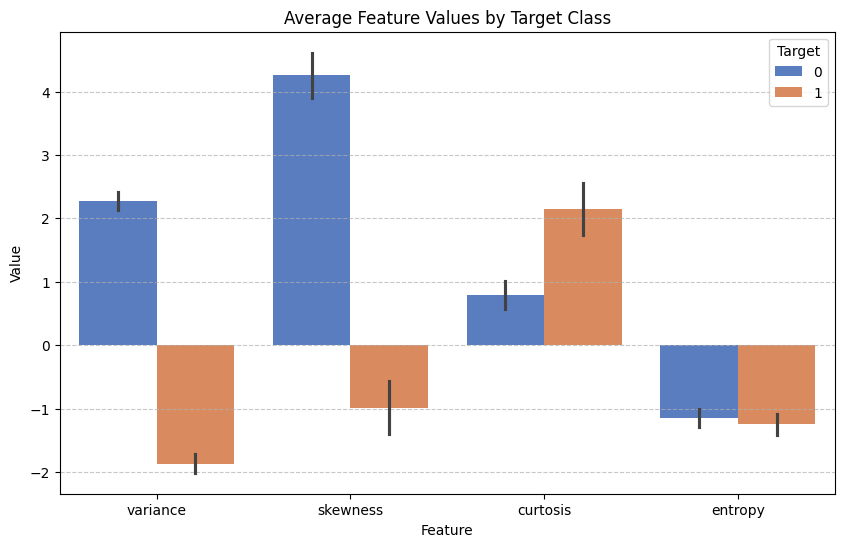

In [12]:
# 2. Barplot (Mean feature values per target class)
df_melted = df.melt(id_vars='Target', var_name='Feature', value_name='Value')

plt.figure(figsize=(10, 6))
sns.barplot(data=df_melted, x='Feature', y='Value', hue='Target', palette='muted')
plt.title('Average Feature Values by Target Class')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

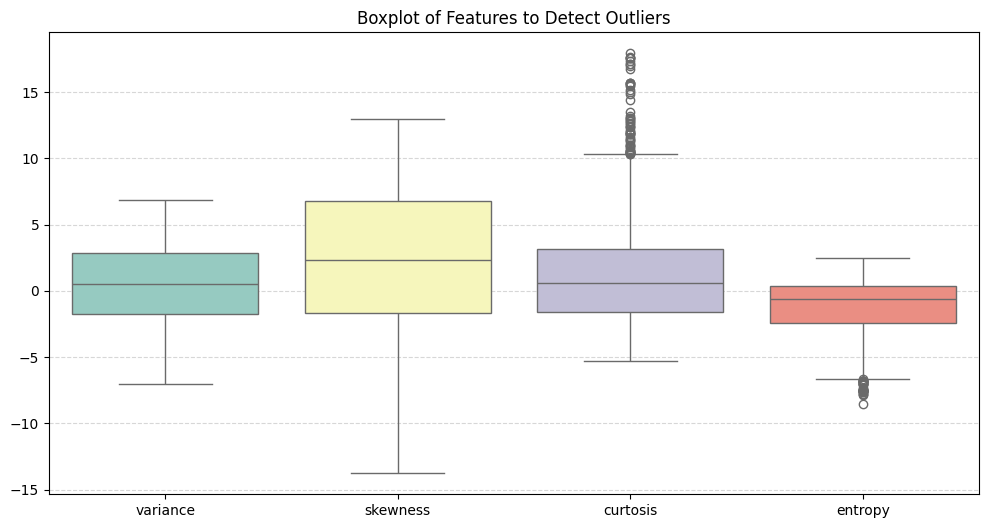

In [13]:
# 3. Boxplots to Check for Outliers
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.drop(columns=['Target']), palette='Set3')
plt.title('Boxplot of Features to Detect Outliers')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

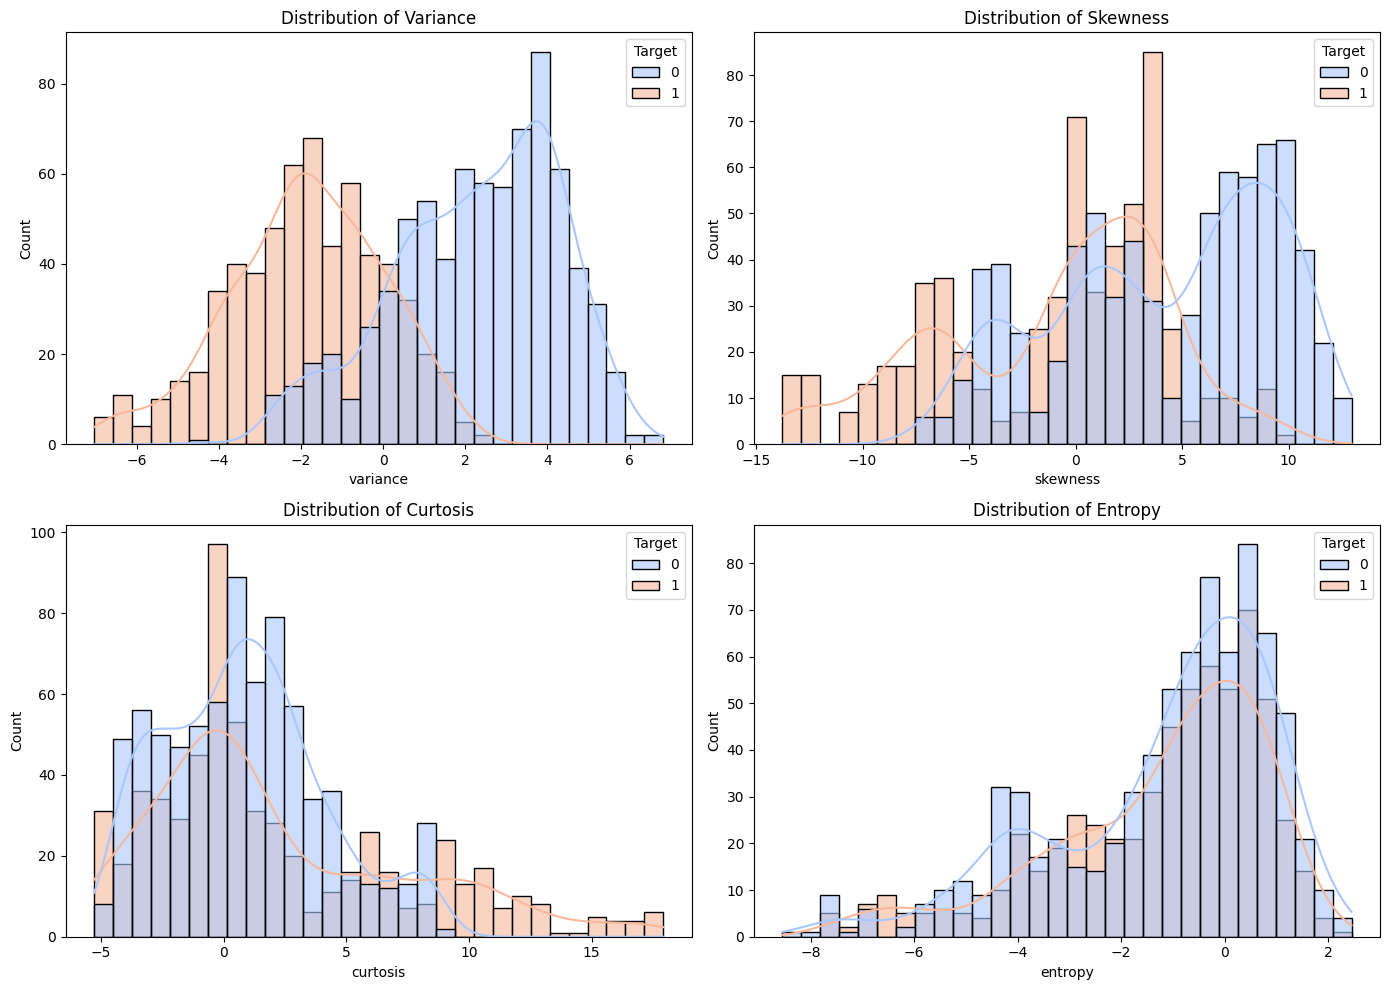

In [14]:
# 4. Histograms and Histogram + KDE
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
features = ['variance', 'skewness', 'curtosis', 'entropy']

for i, col in enumerate(features):
    ax = axes[i//2, i%2]
    # Histogram + KDE
    sns.histplot(data=df, x=col, hue='Target', kde=True, bins=30, ax=ax, palette='coolwarm', alpha=0.6)
    ax.set_title(f'Distribution of {col.capitalize()}')

plt.tight_layout()
plt.show()

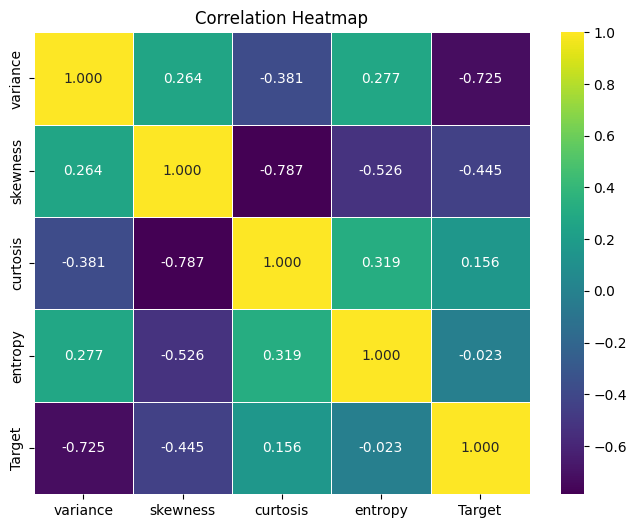

In [15]:
# 5. Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='viridis', fmt='.3f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

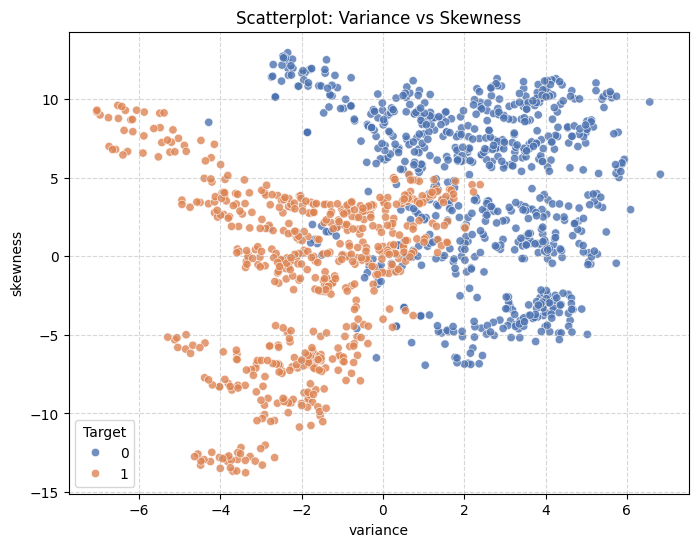

In [16]:
# 6. Scatterplot (Variance vs Skewness colored by Target Class)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='variance', y='skewness', hue='Target', palette='deep', alpha=0.8)
plt.title('Scatterplot: Variance vs Skewness')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [21]:
# The target column is named 'Target' and is already encoded.
print("Unique target values:", df["Target"].unique())
print(df[["Target"]].head(5))

Unique target values: [0 1]
   Target
0       0
1       0
2       0
3       0
4       0


In [23]:
print("Class mapping:")
print("0 -> Genuine")
print("1 -> Forged")

Class mapping:
0 -> Genuine
1 -> Forged


In [24]:
numerical_features=df.select_dtypes(include=np.number).columns
print("Numerical Features:")
print(numerical_features.tolist())

Numerical Features:
['variance', 'skewness', 'curtosis', 'entropy', 'Target']


In [26]:
# 'Target' is already numerical and represents the class labels
X = df.drop(columns=['Target'])
y = df["Target"]
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (1372, 4)
Shape of y: (1372,)


In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
print("Training samples",X_train.shape[0])
print("Testing samples",X_test.shape[0])

Training samples 1097
Testing samples 275


In [28]:
GaussianNB()

GaussianNB()

In [32]:
gnb=GaussianNB()
gnb.fit(X_train,y_train)
y_pred=gnb.predict(X_test)
print("Predicted labels:\n",y_pred)

Predicted labels:
 [0 1 0 1 1 0 0 0 1 1 0 1 0 0 0 0 1 1 1 0 0 1 1 0 0 1 1 1 0 0 0 0 0 1 1 1 0
 1 0 0 1 0 1 0 1 1 0 0 0 1 0 1 1 0 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0
 0 1 1 0 0 1 1 0 1 1 0 1 1 1 1 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 1
 1 0 0 1 0 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0 0 1 1 1 0 0 1 1 1 1 1 0 1 0 1 0 0
 0 0 0 0 1 1 0 0 1 0 1 0 1 0 1 0 0 0 0 1 0 0 1 1 1 0 1 0 1 0 0 1 0 0 1 0 0
 1 1 1 1 1 0 1 0 1 0 1 1 1 1 1 0 0 1 1 1 0 1 0 1 1 1 0 1 1 0 0 1 1 0 1 0 1
 1 1 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 0 0 0 0 0 1 1 0 1 0 0 0 0 1 1 0
 0 1 0 1 1 0 0 1 0 0 1 0 0 0 0 0]


In [35]:
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
print(comparison.head(5))

   Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          1
4       1          1


In [38]:
class_map = {0: "Genuine", 1: "Forged"}
comparison["Actual class"] = comparison["Actual"].map(class_map)
comparison["Predicted class"] = comparison["Predicted"].map(class_map)
comparison.head(5)

,Actual,Predicted,Actual class,Predicted class
0,0,0,Genuine,Genuine
1,1,1,Forged,Forged
2,0,0,Genuine,Genuine
3,1,1,Forged,Forged
4,1,1,Forged,Forged


In [39]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)
print("Accuracy percent",accuracy*100)


Accuracy: 0.8581818181818182
Accuracy percent 85.81818181818181


In [40]:
precision=precision_score(y_test,y_pred)
print("Precision:",precision)

Precision: 0.8487394957983193


In [41]:
recall=recall_score(y_test,y_pred)
print("Recall:",recall)

Recall: 0.8278688524590164


In [42]:
f1=f1_score(y_test,y_pred)
print("F1 score:",f1)

F1 score: 0.8381742738589212


In [45]:
print("Classification Report\n")
print(classification_report(y_test, y_pred, target_names=['Genuine (0)', 'Forged (1)']))

Classification Report

              precision    recall  f1-score   support

 Genuine (0)       0.87      0.88      0.87       153
  Forged (1)       0.85      0.83      0.84       122

    accuracy                           0.86       275
   macro avg       0.86      0.86      0.86       275
weighted avg       0.86      0.86      0.86       275



In [46]:
cm=confusion_matrix(y_test,y_pred)
print("Confusion Matrix:\n",cm)

Confusion Matrix:
 [[135  18]
 [ 21 101]]


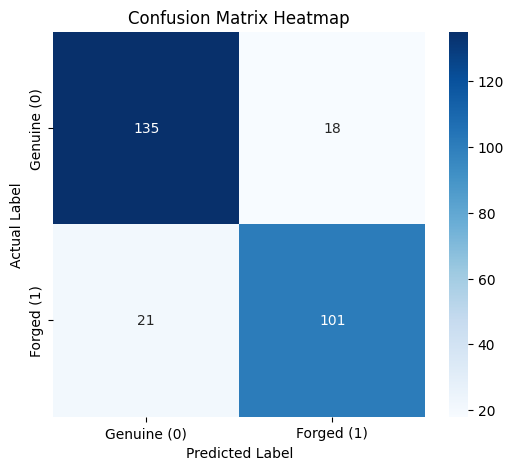

In [47]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Genuine (0)', 'Forged (1)'],
            yticklabels=['Genuine (0)', 'Forged (1)'])
plt.title('Confusion Matrix Heatmap')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

In [48]:
y_train_pred=gnb.predict(X_train)
y_test_pred=gnb.predict(X_test)
train_accuracy=accuracy_score(y_train,y_train_pred)
test_accuracy=accuracy_score(y_test,y_test_pred)
print("Training Accuracy:",train_accuracy)
print("Testing Accuracy:",test_accuracy)


Training Accuracy: 0.8395624430264357
Testing Accuracy: 0.8581818181818182


In [50]:
GaussianNB(var_smoothing=1e-9)
print(gnb.get_params())

{'priors': None, 'var_smoothing': 1e-09}


In [52]:
smoothing_values=[1e-12,1e-10,1e-9,1e-8,1e-7,1e-6,1e-5,1e-4,1e-3,1e-2]
results=[]

for value in smoothing_values:
  model=GaussianNB(var_smoothing=value)
  model.fit(X_train,y_train)
  prediction=model.predict(X_test)
  prec=precision_score(y_test,prediction)
  acc=accuracy_score(y_test,prediction)
  f1_value=f1_score(y_test,prediction)
  rec=recall_score(y_test,prediction)
  results.append((value,acc,prec,rec,f1_value))

In [ ]:
results_df=pd.DataFrame(results,columns=["Smoothing Value","Accuracy","var_smoothing","recall","F1_score"])
